In [1]:
# ============================================================
# STAGE 6 v2 - CELL 1: Setup, Load Data, Rebuild v3 Features
# ============================================================

import numpy as np
import pandas as pd
import os
import joblib
import shap
import matplotlib.pyplot as plt
import xgboost as xgb
from tensorflow.keras.models import load_model
import warnings
warnings.filterwarnings('ignore')

shap.initjs()

PROJECT_ROOT = "C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project"
RESULTS_DIR  = os.path.join(PROJECT_ROOT, "results")
MODELS_DIR   = os.path.join(PROJECT_ROOT, "models")
PLOTS_DIR    = os.path.join(PROJECT_ROOT, "plots")
SEQ_DIR      = os.path.join(RESULTS_DIR, "sequences")

CITIES = ['kano', 'maid', 'abuja']
CITY_LABELS = {'kano': 'Kano', 'maid': 'Maiduguri', 'abuja': 'Abuja'}

# ── Reload sequences and scalers ──
data = {}
for city in CITIES:
    data[city] = {
        'X_test':  np.load(os.path.join(SEQ_DIR, f'X_test_{city}.npy')),
        'y_test':  np.load(os.path.join(SEQ_DIR, f'y_test_{city}.npy')),
        'tgt_scaler': joblib.load(os.path.join(MODELS_DIR, f'tgt_scaler_{city}.pkl')),
    }

# ── Feature index setup (same as build_v3_features relies on) ──
FEATURE_NAMES_17 = [
    'GHI', 'DHI', 'Clearness', 'Temperature', 'Humidity', 'WindSpeed',
    'Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos',
    'DayOfYear_sin', 'DayOfYear_cos', 'Season_encoded', 'Is_Daytime',
    'PV_Power_Lag1', 'PV_Power_Lag24', 'GHI_Lag1'
]
FEATURE_INDEX = {name: i for i, name in enumerate(FEATURE_NAMES_17)}
GHI_IDX, HUMIDITY_IDX, CLEARNESS_IDX = FEATURE_INDEX['GHI'], FEATURE_INDEX['Humidity'], FEATURE_INDEX['Clearness']

FEATURE_NAMES_34 = FEATURE_NAMES_17 + ['CNN_Prediction'] + [
    'GHI_mean_3h', 'GHI_std_3h', 'Humidity_mean_3h', 'Humidity_std_3h',
    'Clearness_mean_3h', 'Clearness_std_3h',
    'GHI_mean_6h', 'GHI_std_6h', 'Humidity_mean_6h', 'Humidity_std_6h',
    'Clearness_mean_6h', 'Clearness_std_6h',
] + ['Season_x_Clearness', 'DayOfYear_x_Humidity', 'Month_x_GHI', 'Season_x_Humidity']

def build_v3_features(X_sequences, cnn_pred_norm):
    last_timestep = X_sequences[:, -1, :]
    cnn_pred_col = cnn_pred_norm.reshape(-1, 1)

    rolling_features = []
    for window in [3, 6]:
        recent_window = X_sequences[:, -window:, :]
        for feat_idx in [GHI_IDX, HUMIDITY_IDX, CLEARNESS_IDX]:
            rolling_features.append(recent_window[:, :, feat_idx].mean(axis=1))
            rolling_features.append(recent_window[:, :, feat_idx].std(axis=1))
    rolling_matrix = np.column_stack(rolling_features)

    season, clearness = last_timestep[:, FEATURE_INDEX['Season_encoded']], last_timestep[:, CLEARNESS_IDX]
    month_cos, doy_cos = last_timestep[:, FEATURE_INDEX['Month_cos']], last_timestep[:, FEATURE_INDEX['DayOfYear_cos']]
    humidity, ghi = last_timestep[:, HUMIDITY_IDX], last_timestep[:, GHI_IDX]

    interactions = np.column_stack([season*clearness, doy_cos*humidity, month_cos*ghi, season*humidity])
    return np.hstack([last_timestep, cnn_pred_col, rolling_matrix, interactions])

# ── Rebuild the 34-feature TEST set (SHAP only needs test data) ──
v3_data = {}
for city in CITIES:
    print(f"Rebuilding v3 features — {CITY_LABELS[city]}...")
    cnn_bilstm_model = load_model(os.path.join(MODELS_DIR, f'best_cnn_bilstm_{CITY_LABELS[city].lower()}.keras'))
    cnn_pred_test = cnn_bilstm_model.predict(data[city]['X_test'], verbose=0).flatten()
    v3_data[city] = {'X_test': build_v3_features(data[city]['X_test'], cnn_pred_test)}

print(f"\n✅ Setup complete — {len(FEATURE_NAMES_34)} features ready for SHAP")

Rebuilding v3 features — Kano...
Rebuilding v3 features — Maiduguri...
Rebuilding v3 features — Abuja...

✅ Setup complete — 34 features ready for SHAP


In [3]:
# ============================================================
# SHAP RE-RUN - CELL 2: Setup for Hybrid v3 (Optuna-Tuned) SHAP
# ============================================================

import shap
import matplotlib.pyplot as plt

shap.initjs()

# Full 34-feature list, in the EXACT order build_v3_features() creates them:
# 17 original + 1 CNN prediction + 12 rolling stats + 4 interactions
FEATURE_NAMES_34 = FEATURE_NAMES_17 + ['CNN_Prediction'] + [
    'GHI_mean_3h', 'GHI_std_3h', 'Humidity_mean_3h', 'Humidity_std_3h',
    'Clearness_mean_3h', 'Clearness_std_3h',
    'GHI_mean_6h', 'GHI_std_6h', 'Humidity_mean_6h', 'Humidity_std_6h',
    'Clearness_mean_6h', 'Clearness_std_6h',
] + [
    'Season_x_Clearness', 'DayOfYear_x_Humidity', 'Month_x_GHI', 'Season_x_Humidity'
]

print(f"Total features: {len(FEATURE_NAMES_34)}")
assert len(FEATURE_NAMES_34) == v3_data['kano']['X_test'].shape[1], \
    "Mismatch — check build_v3_features() column order"
print("✅ Feature names verified against actual model input shape")

Total features: 34
✅ Feature names verified against actual model input shape


In [4]:
# ============================================================
# SHAP RE-RUN - CELL 3: TreeExplainer + SHAP Values (per city)
# ============================================================

explainers_v3 = {}
shap_values_v3 = {}

for city in CITIES:
    print(f"Computing SHAP values — {CITY_LABELS[city]}...")

    # Load the Optuna-tuned corrector saved in Cell 4
    model = joblib.load(os.path.join(MODELS_DIR, f'xgb_{city}_v3_optuna.pkl'))

    explainers_v3[city] = shap.TreeExplainer(model)
    shap_values_v3[city] = explainers_v3[city].shap_values(v3_data[city]['X_test'])

    print(f"  SHAP values shape: {shap_values_v3[city].shape}\n")

print("✅ SHAP values computed for all three cities (Hybrid v3, Optuna-tuned)")

Computing SHAP values — Kano...
  SHAP values shape: (8736, 34)

Computing SHAP values — Maiduguri...
  SHAP values shape: (8736, 34)

Computing SHAP values — Abuja...
  SHAP values shape: (8736, 34)

✅ SHAP values computed for all three cities (Hybrid v3, Optuna-tuned)


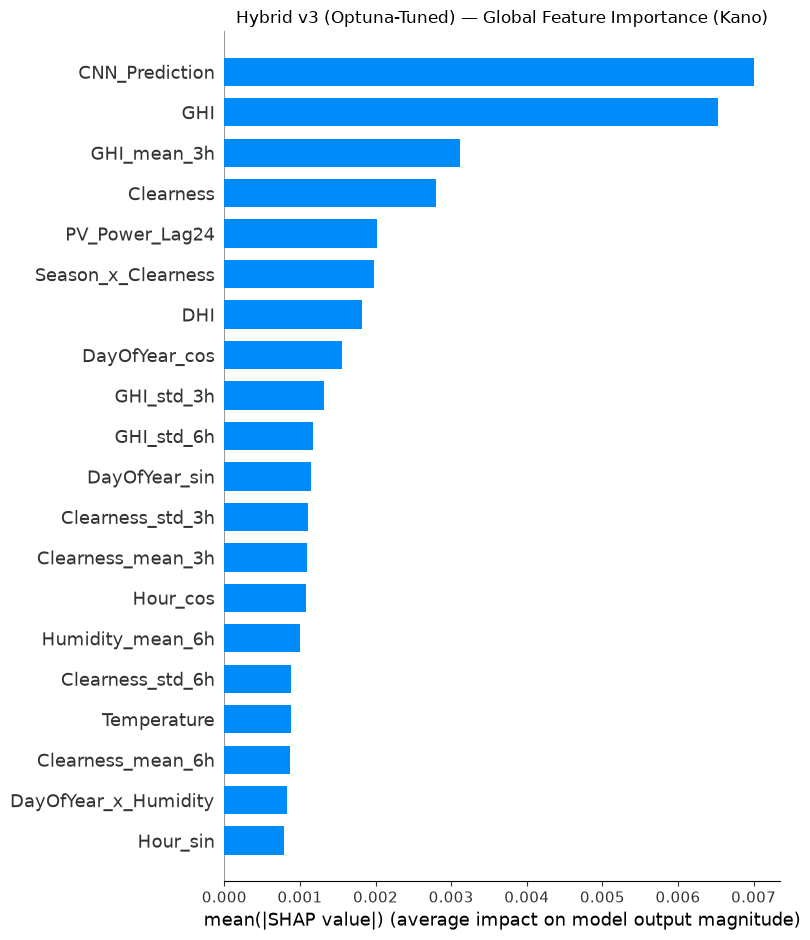

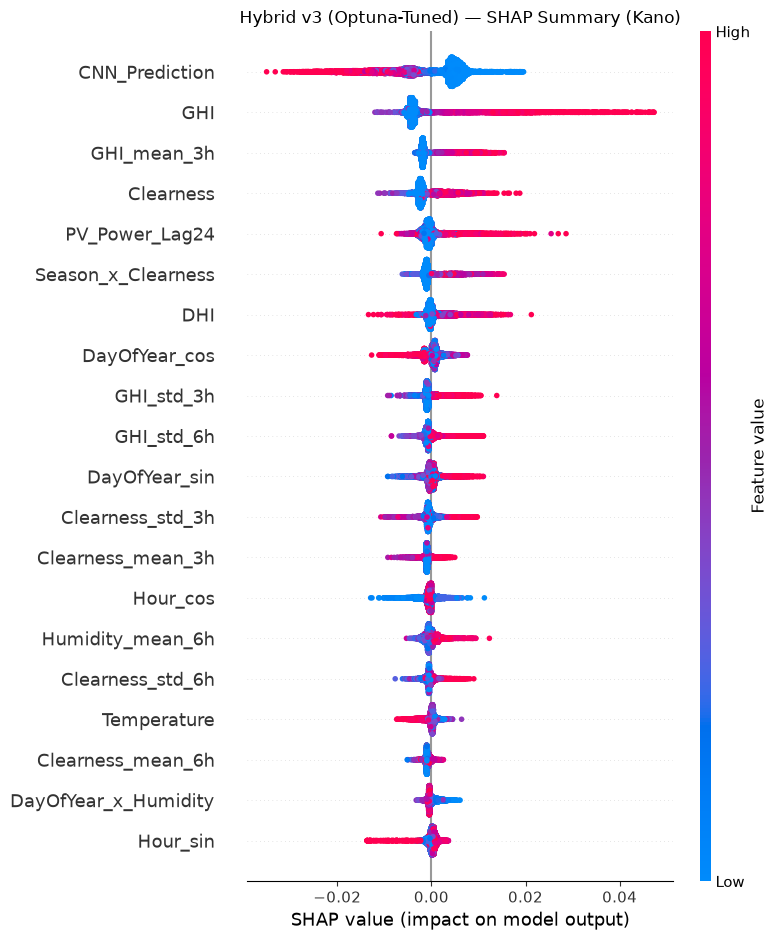

✅ Saved plots for Kano



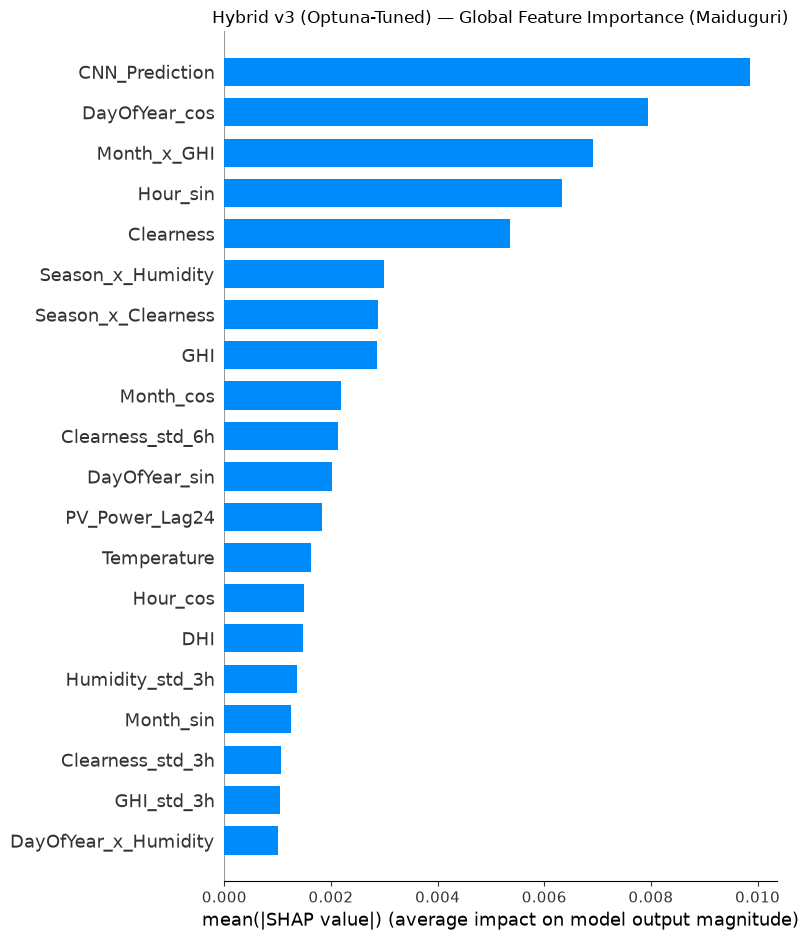

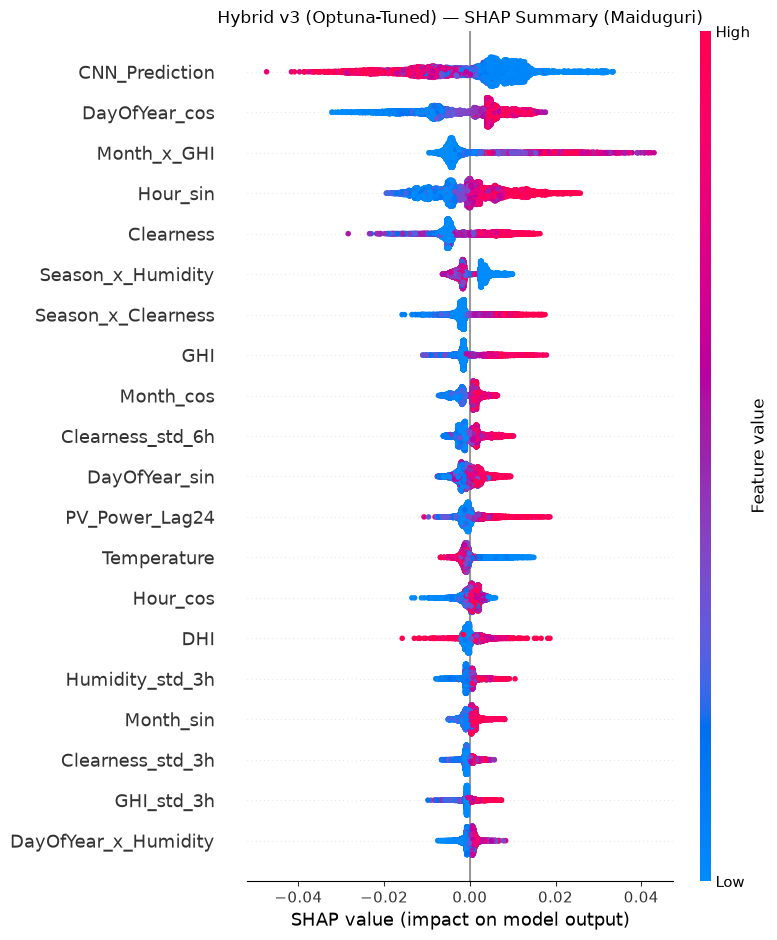

✅ Saved plots for Maiduguri



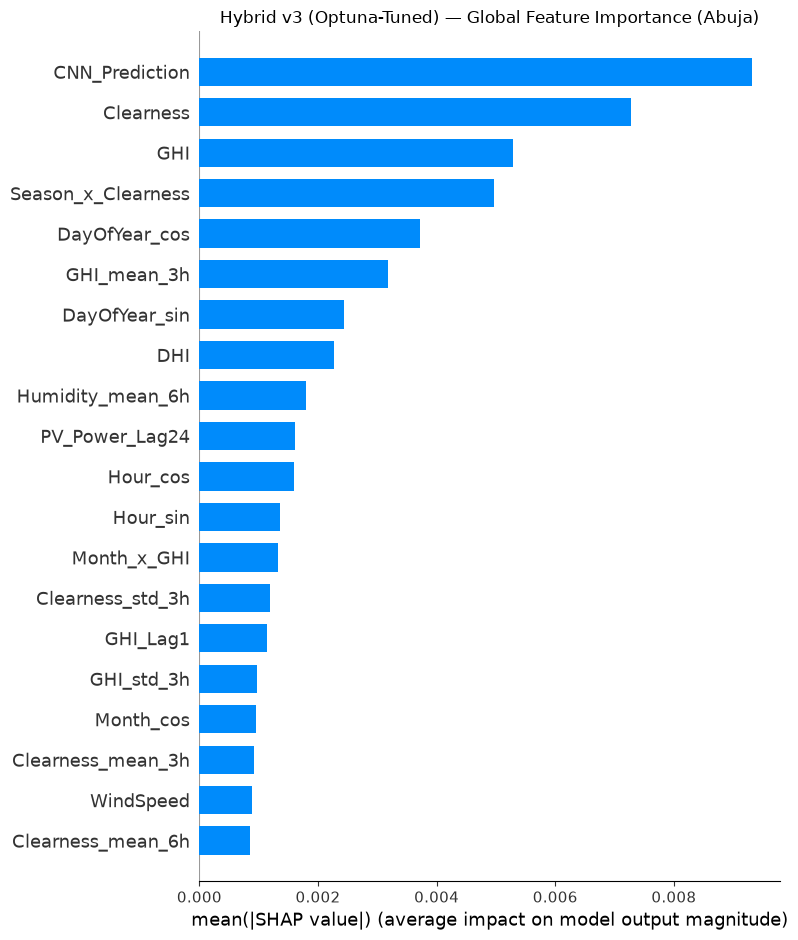

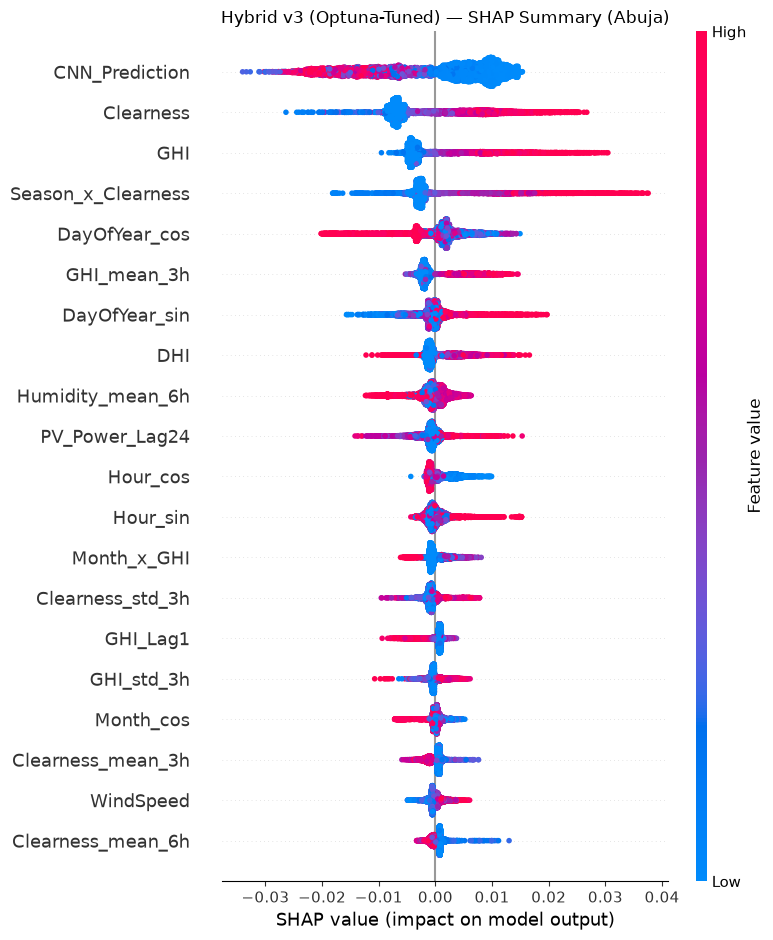

✅ Saved plots for Abuja



In [5]:
# ============================================================
# SHAP RE-RUN - CELL 4: Global Importance Plots
# ============================================================

PLOTS_DIR = os.path.join(PROJECT_ROOT, "plots")

for city in CITIES:
    # Bar plot — overall ranked importance
    plt.figure()
    shap.summary_plot(shap_values_v3[city], v3_data[city]['X_test'],
                       feature_names=FEATURE_NAMES_34, plot_type="bar", show=False)
    plt.title(f"Hybrid v3 (Optuna-Tuned) — Global Feature Importance ({CITY_LABELS[city]})")
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, f"shap_v3optuna_bar_{city}.png"), dpi=300, bbox_inches="tight")
    plt.show()

    # Beeswarm — importance + direction
    plt.figure()
    shap.summary_plot(shap_values_v3[city], v3_data[city]['X_test'],
                       feature_names=FEATURE_NAMES_34, show=False)
    plt.title(f"Hybrid v3 (Optuna-Tuned) — SHAP Summary ({CITY_LABELS[city]})")
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, f"shap_v3optuna_beeswarm_{city}.png"), dpi=300, bbox_inches="tight")
    plt.show()

    print(f"✅ Saved plots for {CITY_LABELS[city]}\n")

In [6]:
# ============================================================
# SHAP RE-RUN - CELL 5: Do the New Engineered Features Matter?
# ============================================================

# This directly tests the claim: "the rolling/interaction features
# we engineered in Lever 1 are genuinely influential, not just noise"

new_feature_names = FEATURE_NAMES_34[18:]   # everything after the original 18

for city in CITIES:
    mean_abs_shap = np.abs(shap_values_v3[city]).mean(axis=0)
    importance_df = pd.DataFrame({
        'Feature': FEATURE_NAMES_34,
        'Mean_Abs_SHAP': mean_abs_shap
    }).sort_values('Mean_Abs_SHAP', ascending=False).reset_index(drop=True)
    importance_df.index += 1

    new_feature_ranks = importance_df[importance_df['Feature'].isin(new_feature_names)]

    print(f"\n{'='*60}\n{CITY_LABELS[city]} — Where do the NEW engineered features rank?\n{'='*60}")
    print(new_feature_ranks.to_string(index=True))
    print(f"\nTop 5 overall:\n{importance_df.head(5).to_string(index=True)}")


Kano — Where do the NEW engineered features rank?
                 Feature  Mean_Abs_SHAP
3            GHI_mean_3h       0.003115
6     Season_x_Clearness       0.001981
9             GHI_std_3h       0.001315
10            GHI_std_6h       0.001176
12      Clearness_std_3h       0.001111
13     Clearness_mean_3h       0.001096
15      Humidity_mean_6h       0.001006
16      Clearness_std_6h       0.000887
18     Clearness_mean_6h       0.000869
19  DayOfYear_x_Humidity       0.000827
21       Humidity_std_6h       0.000697
22           Month_x_GHI       0.000689
26       Humidity_std_3h       0.000496
30      Humidity_mean_3h       0.000448
31           GHI_mean_6h       0.000448
32     Season_x_Humidity       0.000374

Top 5 overall:
          Feature  Mean_Abs_SHAP
1  CNN_Prediction       0.006999
2             GHI       0.006526
3     GHI_mean_3h       0.003115
4       Clearness       0.002798
5  PV_Power_Lag24       0.002024

Maiduguri — Where do the NEW engineered features rank?

In [13]:
# Check what sample #100 actually is
y_true_kw = data['maid']['tgt_scaler'].inverse_transform(data['maid']['y_test'].reshape(-1,1)).flatten()
print(f"Sample #100 actual power: {y_true_kw[100]:.2f} kW")

Sample #100 actual power: 0.00 kW


In [14]:
# Find high-power (clearly daytime) sample indices to use for the waterfall plot
y_true_kw = data['maid']['tgt_scaler'].inverse_transform(data['maid']['y_test'].reshape(-1,1)).flatten()
high_power_indices = np.where(y_true_kw > np.percentile(y_true_kw, 90))[0]
print(f"Top 10 candidate indices (high power hours): {high_power_indices[:10]}")
print(f"Example — Sample #{high_power_indices[0]} actual power: {y_true_kw[high_power_indices[0]]:.2f} kW")

Top 10 candidate indices (high power hours): [12 13 36 37 59 60 61 83 84 85]
Example — Sample #12 actual power: 681.77 kW


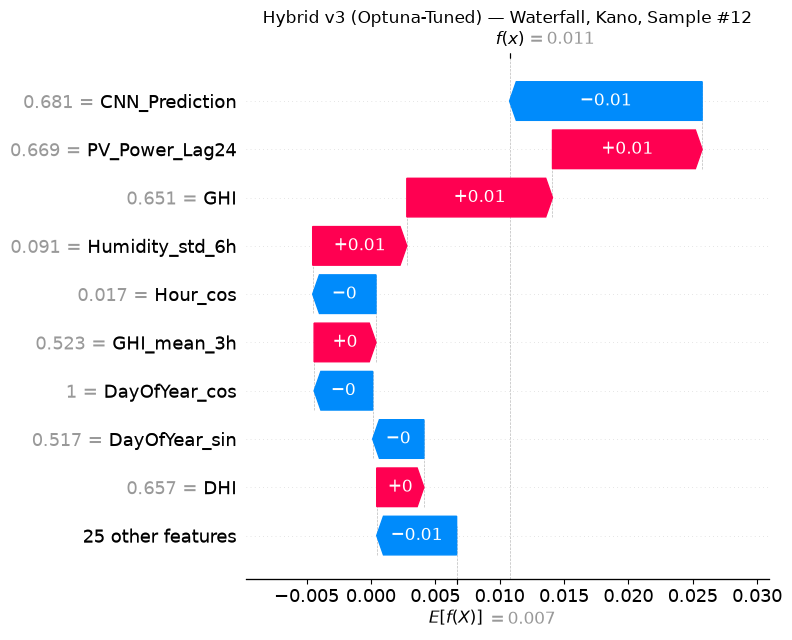

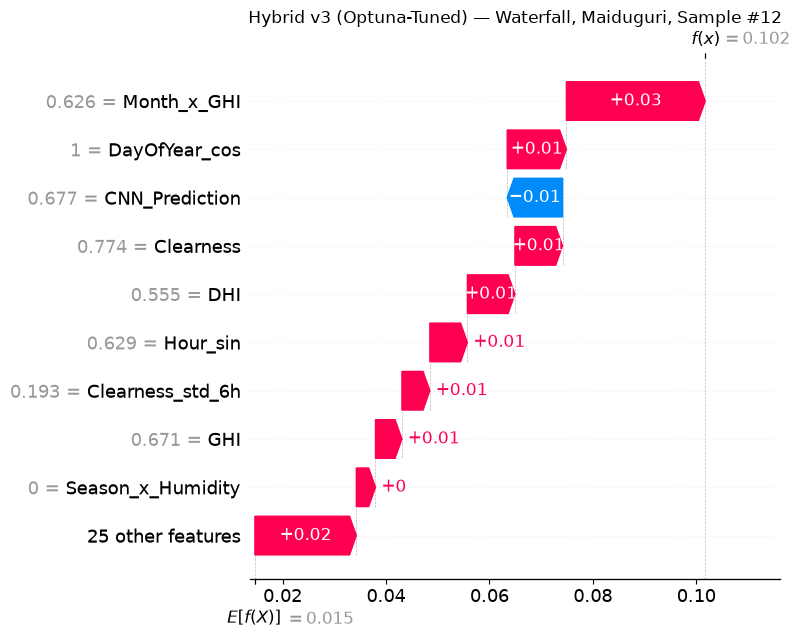

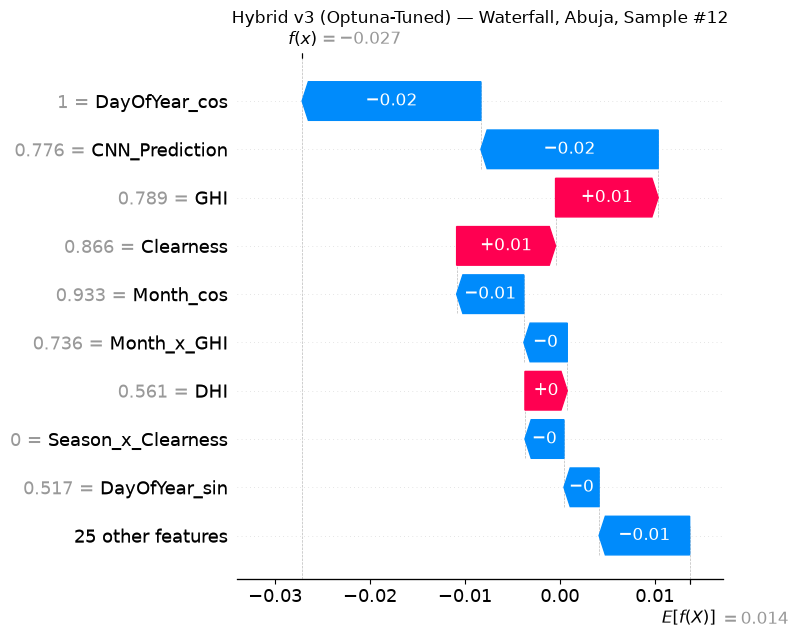

In [15]:
# ============================================================
# SHAP RE-RUN - CELL 6: Waterfall Plot (single prediction example)
# ============================================================

for city in CITIES:
    sample_idx = 12   # adjust if this lands on a low-activity hour

    explanation = shap.Explanation(
        values=shap_values_v3[city][sample_idx],
        base_values=explainers_v3[city].expected_value,
        data=v3_data[city]['X_test'][sample_idx],
        feature_names=FEATURE_NAMES_34
    )
    plt.figure()
    shap.plots.waterfall(explanation, show=False)
    plt.title(f"Hybrid v3 (Optuna-Tuned) — Waterfall, {CITY_LABELS[city]}, Sample #{sample_idx}")
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, f"shap_v3optuna_waterfall_{city}.png"), dpi=300, bbox_inches="tight")
    plt.show()